# Data harmonization

Prepare the soil-carbon and fire-weather tables used by `transformer_walkthrough.ipynb`.
Run this notebook first, then run the modeling notebook.

Soil processing follows `Hawaii_Soils_Transformer.ipynb`.
Fire weather matching and time alignment follow `fireWeatherTransformer.ipynb`, using the bins saved with the included weights.

In [1]:
from pathlib import Path
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data"
INPUTS = DATA / "harmonization"
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True})

## Soil carbon

The input files contain observations before smoothing or time alignment. They share four site IDs:

| File | Contents |
|---|---|
| `soil_landsat.csv` | Acquisition dates, sensor names, original band columns and QA flags |
| `soil_climate.csv` | Monthly TerraClimate observations |
| `soil_sites.csv` | Carbon labels and terrain values |

Data values are perturbed by at most 2.5% to preserve and respect data sovereignty. Carbon and terrain retain the perturbations in the existing soil sample. Coordinates and source IDs are omitted. Acquisition dates and QA flags are retained. The sample includes Landsat 7, 8 and 9; Landsat 5 has no observations in 2014–2024.

In [2]:
landsat = pd.read_csv(INPUTS / "soil_landsat.csv", parse_dates=["date"])
climate = pd.read_csv(INPUTS / "soil_climate.csv", parse_dates=["date"])
sites = pd.read_csv(INPUTS / "soil_sites.csv")
landsat["year"] = landsat.date.dt.year
landsat["month"] = landsat.date.dt.month
landsat["day"] = landsat.date.dt.day
climate = climate.sort_values(["site_id", "date"])
display(landsat.groupby(["site_id", "sensor"]).size().unstack(fill_value=0))

sensor,landsat_7,landsat_8,landsat_9
site_id,,,
site_01,1480,4800,1360
site_02,612,1518,498
site_03,256,984,268
site_04,145,694,184


### Match observations to sites

The bundled tables are already matched by site. With the full soil database, first find each site's nearest entry in each `*_unique_locs` table, then read observations using `unique_loc_id`. These helpers perform that step without changing the database.

The source database stores longitude in `lat` and latitude in `lon`. The matching call below retains the source notebook's coordinate order.

```python
soil_points = pd.read_csv("combined_soc_2024_04_05.csv")
matched_sites = match_soil_locations(soil_points, "Hawaii_Soils_Data_Unique.db")
result = get_matching_rows(matched_sites.iloc[0], "Hawaii_Soils_Data_Unique.db")
```

For a public extract, replace the location IDs with a shared `site_id` and export only dates, measurements and QA flags, as in the bundled input files.

In [3]:
def haversine_vectorized(lat1, lon1, lat2, lon2):
    """
    Vectorized calculation of the great-circle distance (Haversine formula)
    between two sets of latitude and longitude points.
    """
    R = 6371000  # Radius of Earth in meters
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    delta_lat = lat2[:, None] - lat1
    delta_lon = lon2[:, None] - lon1

    a = np.sin(delta_lat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2[:, None]) * np.sin(delta_lon / 2.0) ** 2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return R * c

def find_nearest_points_batched(source_lats, source_lons, target_lats, target_lons, target_ids, batch_size=1000):
    """
    Find nearest target points for each source point using batched processing to save memory.

    Args:
        source_lats, source_lons: Arrays of source coordinates
        target_lats, target_lons: Arrays of target coordinates
        target_ids: Array of target IDs to return
        batch_size: Number of source points to process at once

    Returns:
        Array of nearest target IDs for each source point
    """
    n_source = len(source_lats)
    nearest_ids = np.zeros(n_source, dtype=target_ids.dtype)

    # Process source points in batches
    for i in range(0, n_source, batch_size):
        end_idx = min(i + batch_size, n_source)
        batch_lats = source_lats[i:end_idx]
        batch_lons = source_lons[i:end_idx]

        # Compute distances from this batch to all target points
        distances = haversine_vectorized(batch_lats, batch_lons, target_lats, target_lons)

        # Find nearest target for each point in this batch
        nearest_indices = np.argmin(distances, axis=0)
        nearest_ids[i:end_idx] = target_ids[nearest_indices]

        # Optional: print progress for large datasets
        if n_source > 5000:
            print(f"  Processed {end_idx}/{n_source} points")

    return nearest_ids

def match_soil_locations(soil_points, db_path):
    matched = soil_points.copy()
    source_x = -pd.to_numeric(matched.longitude).abs().to_numpy()
    source_y = pd.to_numeric(matched.latitude).abs().to_numpy()
    uri = Path(db_path).resolve().as_uri() + "?mode=ro"
    with sqlite3.connect(uri, uri=True) as conn:
        tables = conn.execute(
            "SELECT name FROM sqlite_master WHERE type='table' AND name LIKE '%_unique_locs'"
        ).fetchall()
        for (table,) in tables:
            locations = pd.read_sql_query(f'SELECT id, lat, lon FROM "{table}"', conn)
            if locations.empty:
                continue
            matched[f"{table}_id"] = find_nearest_points_batched(
                source_x, source_y,
                locations.lat.to_numpy(float), locations.lon.to_numpy(float),
                locations.id.to_numpy(),
            )
    return matched


def get_matching_rows(soil_row, db_path):
    """
    Given a row from soils_csv, find all matching rows from the _unique_locs tables
    where the lat_lon_id column matches any corresponding ID from the table.

    Parameters:
        soil_row (pd.Series): A single row from the soils_csv DataFrame.
        db_path (str): Path to the SQLite database.

    Returns:
        dict: A dictionary where keys are table names and values are DataFrames of matching rows.
    """
    import pandas as pd

    def add_year_month(df):
        """
        Adds 'year' and 'month' columns to the DataFrame based on the format of part_0 and part_2.
        If part_2 exists, it's in YYYYMMDD format.
        If only part_0 exists, it's in YYYYMM format.
        """
        if "part_2" in df.columns:
            df["year"] = df["part_2"].astype(str).str[:4].astype(int)
            df["month"] = df["part_2"].astype(str).str[4:6].astype(int)
            df["day"] = df["part_2"].astype(str).str[6:8].astype(int)
            df = df.sort_values(by=["year", "month", "day"], ascending=True, na_position="last")

        elif "part_0" in df.columns and df["part_0"].notna().any():
            df.loc[df["part_0"].notna(), "year"] = df["part_0"].astype(str).str[:4].astype("Int64")
            df.loc[df["part_0"].notna(), "month"] = df["part_0"].astype(str).str[4:6].astype("Int64")
            df = df.sort_values(by=["year", "month" ], ascending=True, na_position="last")

        return df

    conn = sqlite3.connect(Path(db_path).resolve().as_uri() + "?mode=ro", uri=True)
    cursor = conn.cursor()

    # Get all tables ending in '_unique_locs'
    cursor.execute("SELECT name FROM sqlite_master WHERE type='table' AND name LIKE '%_unique';")
    tables = [row[0] for row in cursor.fetchall()]
    # print(tables)
    matching_rows = {}

    for table_name in tables:
        # Construct the column name that should exist in soils_csv
        matching_column = f"{table_name}_locs_id"
        # print(matching_column)
        # Check if the column exists in soils_csv
        if matching_column in soil_row:
            match_id = soil_row[matching_column].astype(str)
            # print(table_name)
            if pd.notna(match_id):  # Ensure it's not NaN
              query = f"SELECT * FROM `{table_name}` WHERE unique_loc_id = ?;"
              df = pd.read_sql_query(query, conn, params=(match_id,))
              df = add_year_month(df)
            if not df.empty:
                matching_rows[table_name] = df  # Store matching rows

    conn.close()
    return matching_rows

### Align bands and filter observations

Map each sensor's band numbers to the same band names. Remove cloud, cloud-shadow and snow observations using `QA_PIXEL`, then remove values outside three standard deviations within each sensor and band. Values stay on the source scale used by the saved model.

In [4]:
landsat_band_alignment = {
    "Blue": {
        "landsat_5_unique": "SR_B1",
        "landsat_7_unique": "SR_B1",
        "landsat_8_unique": "SR_B2",
        "landsat_9_unique": "SR_B2",
    },
    "Green": {
        "landsat_5_unique": "SR_B2",
        "landsat_7_unique": "SR_B2",
        "landsat_8_unique": "SR_B3",
        "landsat_9_unique": "SR_B3",
    },
    "Red": {
        "landsat_5_unique": "SR_B3",
        "landsat_7_unique": "SR_B3",
        "landsat_8_unique": "SR_B4",
        "landsat_9_unique": "SR_B4",
    },
    "NIR": {
        "landsat_5_unique": "SR_B4",
        "landsat_7_unique": "SR_B4",
        "landsat_8_unique": "SR_B5",
        "landsat_9_unique": "SR_B5",
    },
    "SWIR-1": {
        "landsat_5_unique": "SR_B5",
        "landsat_7_unique": "SR_B5",
        "landsat_8_unique": "SR_B6",
        "landsat_9_unique": "SR_B6",
    },
    "SWIR-2": {
        "landsat_5_unique": "SR_B7",
        "landsat_7_unique": "SR_B7",
        "landsat_8_unique": "SR_B7",
        "landsat_9_unique": "SR_B7",
    },
    "Panchromatic": {
        "landsat_7_unique": "SR_B8",
        "landsat_8_unique": "SR_B8",
        "landsat_9_unique": "SR_B8",
    },
    "Cirrus": {
        "landsat_8_unique": "SR_B9",
        "landsat_9_unique": "SR_B9",
    },
    "Thermal-1": {
        "landsat_5_unique": "SR_B6",
        "landsat_7_unique": "SR_B6",
        "landsat_8_unique": "SR_B10",
        "landsat_9_unique": "SR_B10",
    },
    "Thermal-2": {
        "landsat_8_unique": "SR_B11",
        "landsat_9_unique": "SR_B11",
    },
}

def align_landsat_bands(data_tables, band_alignment):
    """Aligns Landsat band columns in the given data tables based on the band_alignment dictionary."""

    aligned_data_tables = {}

    for landsat_version in ["landsat_5_unique", "landsat_7_unique", "landsat_8_unique", "landsat_9_unique"]:
        df = data_tables[landsat_version].copy()  # Keep original columns

        # Extract mapping for this Landsat version
        mapping = {v: k for k, d in band_alignment.items() if (v := d.get(landsat_version))}

        # Create a new DataFrame with mapped columns but do not remove any existing columns
        for orig_col, new_name in mapping.items():
            if orig_col in df.columns:
                df[new_name] = df[orig_col]  # Copy original column to new mapped name
            else:
                df[new_name] = float("nan")  # Add NaN if missing

        # Store updated DataFrame
        aligned_data_tables[landsat_version] = df

    return aligned_data_tables

def decode_qa_pixel(qa_pixel):
    if pd.isna(qa_pixel):
        return {'Cloud': 1, 'Cloud Shadow': 1, 'Snow': 1, 'Clear': 0}  # Assume NaN means bad data

    qa_pixel = int(qa_pixel)

    return {
        'Cloud': (qa_pixel >> 3) & 1,
        'Cloud Shadow': (qa_pixel >> 4) & 1,
        'Snow': (qa_pixel >> 5) & 1,
        'Clear': (qa_pixel >> 6) & 1,
    }

### Smooth and align dates

The source LOWESS function combines the sensors by band, smooths the observations, and interpolates onto a shared 30-day grid. The training preparation uses `frac_n=0.04` and `n_std=3`.

In [5]:
def create_loess_smoothed_dataframe(harmonized_data, bands_to_plot, n_std=3, frac_n=0.035, interval_days=1):
    all_bands_data = []  # Collect all bands into one DataFrame before LOESS

    for band in bands_to_plot:
        band_data = []  # Collect all Landsat versions for this band

        for landsat_version, df in harmonized_data.items():
            if band in df.columns and "QA_PIXEL" in df.columns:
                # Filter and clean the data
                df_filtered = df[(df["year"] >= 2014) & (df["year"] <= 2024)].copy()
                df_filtered.loc[:, "QA_PIXEL"] = df_filtered["QA_PIXEL"].fillna(0).astype(int)
                qa_decoded = df_filtered["QA_PIXEL"].apply(decode_qa_pixel)
                df_filtered = df_filtered[
                    (qa_decoded.apply(lambda x: x['Cloud']) == 0) &
                    (qa_decoded.apply(lambda x: x['Cloud Shadow']) == 0) &
                    (qa_decoded.apply(lambda x: x['Snow']) == 0)
                ]
                df_filtered.loc[:, band] = df_filtered[band].fillna(np.nan).astype(float)

                # Apply standard deviation filtering
                band_mean = df_filtered[band].mean()
                band_std = df_filtered[band].std()
                df_filtered = df_filtered[
                    (df_filtered[band] > band_mean - n_std * band_std) &
                    (df_filtered[band] < band_mean + n_std * band_std)
                ]

                if not df_filtered.empty:
                    df_filtered.loc[:, 'date'] = pd.to_datetime(df_filtered[['year', 'month', 'day']])
                    df_filtered.sort_values('date', inplace=True)
                    band_data.append(df_filtered[['date', band]])  # Collect data for this band

        if band_data:
            # Merge all versions for this band
            combined_band_df = pd.concat(band_data, ignore_index=True).drop_duplicates(subset='date')
            combined_band_df.set_index('date', inplace=True)
            all_bands_data.append(combined_band_df)  # Collect all bands for merging later

    if not all_bands_data:
        return pd.DataFrame()  # If no data, return empty DataFrame

    # Merge all bands on 'date' index
    full_data = pd.concat(all_bands_data, axis=1).sort_index()

    # Generate a uniform date range
    date_range = pd.date_range(start=full_data.index.min(), end=full_data.index.max(), freq=f'{interval_days}D')

    # Apply LOESS smoothing for each band, aligned on the same date range
    smoothed_data = {'date': date_range}

    for band in bands_to_plot:
        if band in full_data.columns:
            loess_result = lowess(full_data[band].dropna(), full_data[band].dropna().index, frac=frac_n)
            df_smoothed = pd.Series(index=pd.to_datetime(loess_result[:, 0]), data=loess_result[:, 1])
            df_smoothed = df_smoothed.reindex(df_smoothed.index.union(date_range)).interpolate(method='time').reindex(date_range)
            smoothed_data[f'{band}'] = df_smoothed.values

    # Convert smoothed results to a DataFrame
    final_df = pd.DataFrame(smoothed_data)

    return final_df

### Join climate, terrain and carbon

For each site, join the latest monthly climate record at or before each 30-day timestamp. Repeat the site's terrain values and carbon label across its records, and compute the seasonal features used by the model.

In [6]:
REFLECTANCE = ["Blue", "Green", "Red", "NIR", "SWIR-1", "SWIR-2"]
CLIMATE = ["aet", "def", "pdsi", "pet", "pr", "ro", "soil", "srad", "swe", "tmmn", "tmmx", "vap", "vpd", "vs"]
STATIC = ["SRTM", "slope", "elevation", "aspect_sin", "aspect_cos", "imp_c"]
SOIL_FEATURES = ["doy_sin", "doy_cos"] + REFLECTANCE + CLIMATE + STATIC

soil_frames = []
for _, site in sites.iterrows():
    observed = landsat[landsat.site_id == site.site_id]
    tables = {
        f"landsat_{sensor}_unique": observed[observed.sensor == f"landsat_{sensor}"].copy()
        for sensor in [5, 7, 8, 9]
    }
    aligned = align_landsat_bands(tables, landsat_band_alignment)
    aligned = {name: frame for name, frame in aligned.items() if not frame.empty}
    smoothed = create_loess_smoothed_dataframe(
        aligned, REFLECTANCE, n_std=3, frac_n=0.04, interval_days=30
    )
    monthly = climate[climate.site_id == site.site_id][["date"] + CLIMATE]
    merged = pd.merge_asof(smoothed.sort_values("date"), monthly.sort_values("date"), on="date")
    merged["doy_sin"] = np.sin(merged.date.dt.dayofyear / 365)
    merged["doy_cos"] = np.cos(merged.date.dt.dayofyear / 365)
    for name in STATIC:
        merged[name] = float(site[name])
    merged.insert(0, "site_id", site.site_id)
    if not np.isfinite(merged[SOIL_FEATURES].to_numpy(float)).all():
        raise ValueError(f"Incomplete covariates for {site.site_id}")
    soil_frames.append(merged[["site_id", "date"] + SOIL_FEATURES])

soil_harmonized = pd.concat(soil_frames, ignore_index=True)
display(soil_harmonized.groupby("site_id").agg(records=("date", "size"), first=("date", "min"), last=("date", "max")))
display(soil_harmonized.head())

,records,first,last
site_id,,,
site_01,134,2014-01-16,2024-12-19
site_02,134,2014-01-16,2024-12-19
site_03,134,2014-01-02,2024-12-05
site_04,134,2014-01-02,2024-12-05


,site_id,date,doy_sin,doy_cos,Blue,Green,Red,NIR,SWIR-1,SWIR-2,aet,def,pdsi,pet,pr,ro,soil,srad,swe,tmmn,tmmx,vap,vpd,vs,SRTM,slope,elevation,aspect_sin,aspect_cos,imp_c
0,site_01,2014-01-16,0.043822,0.999039,8423.352866,9298.998812,9514.551715,11326.877274,10758.951449,10280.567292,860.85395,110.35157,-259.85440,950.47644,80.68050,4.08387,173.84963,1582.08799,0.0,178.42625,257.47664,1903.38444,82.01284,314.68804,0.0,0.55844,19.012,-0.99295,0.11851,1.3565
1,site_01,2014-02-15,0.125694,0.992069,8418.004221,9332.702121,9588.165052,11352.192974,10855.520455,10412.338258,824.59827,42.65088,-206.00660,850.73706,82.41876,4.06439,155.56429,1626.61206,0.0,192.38286,255.97177,1996.52896,81.44052,222.86048,0.0,0.55844,19.012,-0.99295,0.11851,1.3565
2,site_01,2014-03-17,0.206718,0.978401,8419.016963,9375.462009,9670.983650,11384.376435,10954.932294,10546.881263,746.52459,526.03072,-183.79313,1248.26436,72.13916,4.06883,114.06890,2124.22216,0.0,185.15998,260.53929,1912.51480,89.10441,316.37217,0.0,0.55844,19.012,-0.99295,0.11851,1.3565
3,site_01,2014-04-16,0.286346,0.958126,8488.457995,9499.828917,9838.110098,11497.975378,11125.497437,10733.164741,199.30828,1316.71054,-252.54019,1487.80381,17.71377,1.02244,90.67007,2419.13705,0.0,200.78786,268.57187,2051.52561,96.08692,522.51406,0.0,0.55844,19.012,-0.99295,0.11851,1.3565
4,site_01,2014-05-16,0.364041,0.931383,8649.656294,9734.830255,10126.233064,11701.718399,11259.496364,10914.489152,1116.67362,321.88987,-137.26098,1402.85795,113.36092,6.13544,74.99972,2496.61131,0.0,204.24657,282.16858,2103.52029,105.79294,181.61047,0.0,0.55844,19.012,-0.99295,0.11851,1.3565


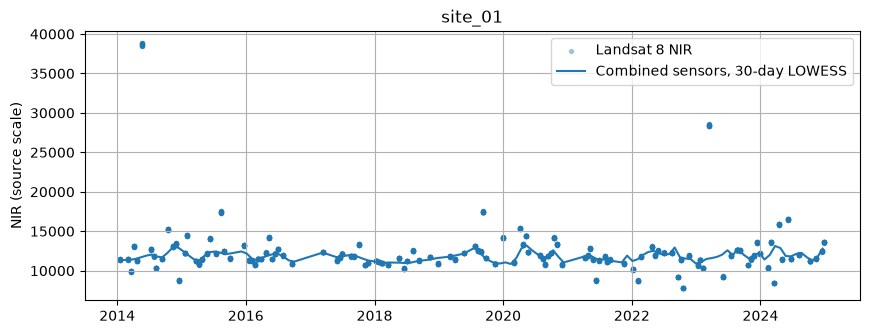

In [7]:
site_id = sites.site_id.iloc[0]
observed = landsat[(landsat.site_id == site_id) & (landsat.sensor == "landsat_8")]
qa = observed.QA_PIXEL.fillna(0).astype(int)
observed = observed[(qa & 56) == 0]
prepared = soil_harmonized[soil_harmonized.site_id == site_id]
fig, ax = plt.subplots()
ax.scatter(observed.date, observed.SR_B5, s=8, alpha=0.35, label="Landsat 8 NIR")
ax.plot(prepared.date, prepared.NIR, label="Combined sensors, 30-day LOWESS")
ax.set(title=site_id, ylabel="NIR (source scale)")
ax.legend()
plt.show()

soil_harmonized.to_csv(DATA / "soil_carbon_harmonized.csv", index=False, date_format="%Y-%m-%d")

## Fire weather

Match each fire to weather grid points, turn bubble radii into daily diameter distributions, then put weather and fire observations on the same six-hour grid.

### Match weather to each fire

The original weather query uses the centroid of the combined fire perimeters and selects the nearest grid point in each weather-grid vintage. The helper below follows that query. Supply fire perimeters and the grid in longitude/latitude coordinates.

```python
import geopandas as gpd

weather_grid = gpd.read_file("cfsv2_coords.gpkg").to_crs(4326)
perimeters = gpd.read_file("fire_perimeters.geojson").to_crs(4326)
weather_for_fire = get_hdwi_range(
    perimeters, "2002-05-16", "2002-06-23", weather_grid, "cfsv2.db"
)
```

The bundled weather extract is already matched. Its grid point was selected using the mean bubble centre and a vintage covering the full sample; the selected coordinates are recorded in `fire_events.json`.

In [8]:
def get_hdwi_range(win_one, start_date, end_date, weather_grid, DB_PATH):
    target_geom = win_one.union_all().centroid
    target_lat, target_lon = target_geom.y, target_geom.x

    nearest_by_vintage = weather_grid.copy()
    nearest_by_vintage["min_date"] = pd.to_datetime(nearest_by_vintage["min_date"]).dt.tz_localize(None)
    nearest_by_vintage["max_date"] = pd.to_datetime(nearest_by_vintage["max_date"]).dt.tz_localize(None)
    nearest_by_vintage["dist"] = (
        (nearest_by_vintage["latitude"] - target_lat) ** 2 +
        (nearest_by_vintage["longitude"] - target_lon) ** 2
    )

    nearest_by_vintage = (
        nearest_by_vintage.sort_values("dist")
        .groupby("min_date", as_index=False)
        .first()
        .sort_values("min_date")
        .reset_index(drop=True)
    )

    con = sqlite3.connect(Path(DB_PATH).resolve().as_uri() + "?mode=ro", uri=True)
    dfs = []

    for _, r in nearest_by_vintage.iterrows():
        tmp = pd.read_sql(
            "SELECT * FROM cfsv2 WHERE latitude = ? AND longitude = ? ORDER BY date",
            con,
            params=(r["latitude"], r["longitude"])
        )
        tmp["source_vintage"] = r["min_date"]
        dfs.append(tmp)

    con.close()

    all_points_df = pd.concat(dfs, ignore_index=True)
    all_points_df["date"] = pd.to_datetime(all_points_df["date"]).dt.tz_localize(None)
    all_points_df["source_vintage"] = pd.to_datetime(all_points_df["source_vintage"]).dt.tz_localize(None)

    start_date = pd.Timestamp(start_date).tz_localize(None)
    end_date = pd.Timestamp(end_date).tz_localize(None)

    range_df = all_points_df[
        (all_points_df["date"] >= start_date) &
        (all_points_df["date"] < end_date)
    ].copy()

    return range_df.sort_values("date").reset_index(drop=True)

### Build daily fire distributions

Convert each radius to diameter, count diameters in the saved model's five bins, and divide by the total count for that day.

In [9]:
fire_config = json.loads((ROOT / "models/fire_config.json").read_text())
WEATHER = fire_config["selected_feature_cols"]
FIRE_BINS = fire_config["fire_target_cols"]
TIME_FEATURES = fire_config["encoder_cols"]
FIRE_FEATURES = WEATHER + FIRE_BINS + TIME_FEATURES
BIN_EDGES = np.array([float(v) for v in fire_config["bin_edges"]])
weather = pd.read_csv(DATA / "fire_weather.csv", parse_dates=["date"])
bubbles = pd.read_csv(DATA / "fire_bubbles.csv", parse_dates=["date"])
events = json.loads((DATA / "fire_events.json").read_text())

rows = []
for (fire_id, day), group in bubbles.groupby(["fire_id", "date"]):
    counts, _ = np.histogram(2 * group.radius_m.to_numpy(), bins=BIN_EDGES)
    frequency = counts / counts.sum()
    rows.append({"fire_id": fire_id, "date": day, **dict(zip(FIRE_BINS, frequency))})
daily_fire = pd.DataFrame(rows)
display(daily_fire.head())

,fire_id,date,bin_00,bin_01,bin_02,bin_03,bin_04
0,2002-NVHTF-001233,2002-06-15,0.292063,0.673016,0.031746,0.003175,0.0
1,2002-NVHTF-001233,2002-06-16,0.294174,0.651385,0.052531,0.001910,0.0
2,2002-NVHTF-001233,2002-06-17,0.324065,0.626558,0.046021,0.003356,0.0
3,2002-NVHTF-001233,2002-06-18,0.313131,0.639913,0.045045,0.001911,0.0
4,2002-NVHTF-001233,2002-06-19,0.327527,0.625357,0.045403,0.001713,0.0


### Align the six-hour records

Use 30 days of weather before each event. Repeat each daily fire distribution at 00:00, 06:00, 12:00 and 18:00. Pre-event fire frequencies are zero and `fire_day` is −1. During the event, `fire_day` is elapsed days divided by 360.

Weather must be present at every timestamp. The bundled sample contains eight consecutive fire-observation days; forecasts are built only where their full targets fit inside those observations.

In [10]:
def make_time_encoders(ts, fire_day):
    ts = pd.Timestamp(ts)

    hour_float = (
        ts.hour
        + ts.minute / 60.0
        + ts.second / 3600.0
        + ts.microsecond / 3_600_000_000.0
    )
    diurnal_phase = 2.0 * np.pi * (hour_float / 24.0)
    diurnal_sin = np.sin(diurnal_phase)
    diurnal_cos = np.cos(diurnal_phase)

    year_len = 366.0 if ts.is_leap_year else 365.0
    doy_zero_based = ts.dayofyear - 1
    annual_phase = 2.0 * np.pi * (doy_zero_based / year_len)
    annual_sin = np.sin(annual_phase)
    annual_cos = np.cos(annual_phase)

    return np.array(
        [diurnal_sin, diurnal_cos, annual_sin, annual_cos, float(fire_day)],
        dtype=np.float32
    )

def make_6h_index(start_ts, end_ts, step_hours, hours_to_keep=None, drop_feb29=False):
    start_ts = pd.Timestamp(start_ts)
    end_ts = pd.Timestamp(end_ts)

    idx = pd.date_range(start_ts, end_ts, freq=f"{step_hours}h")

    if drop_feb29:
        idx = idx[~((idx.month == 2) & (idx.day == 29))]

    if hours_to_keep is not None:
        idx = idx[idx.hour.isin(hours_to_keep)]

    return idx

def map_daily_df_to_subdaily(daily_df, subdaily_idx):
    mapped = daily_df.reindex(subdaily_idx.normalize())
    mapped = pd.DataFrame(
        mapped.to_numpy(dtype=np.float32),
        index=subdaily_idx,
        columns=daily_df.columns
    )
    return mapped

In [11]:
fire_frames = []
for event in events:
    fire_id = event["fire_id"]
    start = pd.Timestamp(event["event_start"])
    last = pd.Timestamp(event["sample_last_day"])
    index = make_6h_index(start - pd.Timedelta(days=30), last + pd.Timedelta(hours=18), 6)
    daily = daily_fire[daily_fire.fire_id == fire_id].set_index("date")[FIRE_BINS]
    days = pd.date_range(index.min().normalize(), last, freq="D")
    daily = daily.reindex(days)
    if daily.loc[start:last].isna().any().any():
        raise ValueError(f"Missing fire observations for {fire_id}")
    daily.loc[daily.index < start] = 0.0
    fire_6h = map_daily_df_to_subdaily(daily, index)
    weather_6h = (weather[weather.fire_id == fire_id]
                  .groupby("date")[WEATHER].first().reindex(index))
    if not np.isfinite(weather_6h.to_numpy(float)).all():
        raise ValueError(f"Missing weather for {fire_id}")
    elapsed = (index.normalize() - start).days
    fire_day = np.where(elapsed < 0, -1.0, elapsed / 360.0)
    encoded = pd.DataFrame(
        [make_time_encoders(ts, day) for ts, day in zip(index, fire_day)],
        index=index, columns=TIME_FEATURES,
    )
    joined = pd.concat([weather_6h, fire_6h, encoded], axis=1)
    joined.index.name = "date"
    joined = joined.reset_index()
    joined.insert(0, "fire_id", fire_id)
    fire_frames.append(joined)

fire_harmonized = pd.concat(fire_frames, ignore_index=True)
assert np.isfinite(fire_harmonized[FIRE_FEATURES].to_numpy()).all()
fire_harmonized.to_csv(DATA / "fire_harmonized.csv", index=False, date_format="%Y-%m-%dT%H:%M:%S")
display(fire_harmonized[["fire_id", "date"] + FIRE_BINS + ["fire_day"]].tail(8))

<ipython-input-11-5786e8e21c23>:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  index = make_6h_index(start - pd.Timedelta(days=30), last + pd.Timedelta(hours=18), 6)
<ipython-input-11-5786e8e21c23>:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  index = make_6h_index(start - pd.Timedelta(days=30), last + pd.Timedelta(hours=18), 6)
<ipython-input-11-5786e8e21c23>:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  index = make_6h_index(start - pd.Timedelta(days=30), last + pd.Timedelta(

,fire_id,date,bin_00,bin_01,bin_02,bin_03,bin_04,fire_day
448,2012-CAMNFC-001109,2012-07-14 00:00:00,0.340510,0.611643,0.045853,0.001994,0.0,0.016667
449,2012-CAMNFC-001109,2012-07-14 06:00:00,0.340510,0.611643,0.045853,0.001994,0.0,0.016667
450,2012-CAMNFC-001109,2012-07-14 12:00:00,0.340510,0.611643,0.045853,0.001994,0.0,0.016667
451,2012-CAMNFC-001109,2012-07-14 18:00:00,0.340510,0.611643,0.045853,0.001994,0.0,0.016667
452,2012-CAMNFC-001109,2012-07-15 00:00:00,0.366106,0.591203,0.041397,0.001294,0.0,0.019444
453,2012-CAMNFC-001109,2012-07-15 06:00:00,0.366106,0.591203,0.041397,0.001294,0.0,0.019444
454,2012-CAMNFC-001109,2012-07-15 12:00:00,0.366106,0.591203,0.041397,0.001294,0.0,0.019444
455,2012-CAMNFC-001109,2012-07-15 18:00:00,0.366106,0.591203,0.041397,0.001294,0.0,0.019444


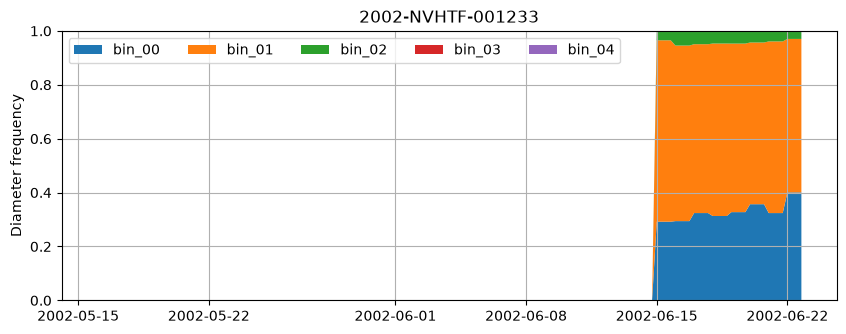

In [12]:
event = events[0]
example = fire_harmonized[fire_harmonized.fire_id == event["fire_id"]]
fig, ax = plt.subplots()
ax.stackplot(example.date, example[FIRE_BINS].to_numpy().T, labels=FIRE_BINS)
ax.set(title=event["fire_id"], ylabel="Diameter frequency", ylim=(0, 1))
ax.legend(loc="upper left", ncol=5)
plt.show()

## Continue to the models

`transformer_walkthrough.ipynb` reads `data/soil_carbon_harmonized.csv` and `data/fire_harmonized.csv`. It applies the saved normalization, constructs sequences, defines the models and runs predictions on the GPU when available. Training is commented out.

The soil output uses all available Landsat sensors and the original LOWESS function.